# Part 1: WEB-02, Explore FIT file data
**Garmin Watch project · Web Development stream**

Goal: find out what data is inside the Garmin FIT files, so we know what the web dashboard can show and store.

Files used: the 3 sample runs in the repo's TestingData folder

In [ ]:
!git clone -q --depth 1 https://github.com/Redback-Operations/garmin-smartwatch.git
!pip install -q fitparse

fatal: destination path 'garmin-smartwatch' already exists and is not an empty directory.


In [ ]:
import os, json
from google.colab import drive
drive.mount('/content/drive')

OUT = "/content/drive/MyDrive/capstone_project"
os.makedirs(OUT, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os, glob
print("Current folder:", os.getcwd())
print("Repo downloaded?", os.path.exists("/content/garmin-smartwatch"))
print(glob.glob("/content/garmin-smartwatch/TestingData/*"))

Current folder: /content
Repo downloaded? True
['/content/garmin-smartwatch/TestingData/brave_OVpZoUQqRg.png', '/content/garmin-smartwatch/TestingData/brave_DspsWicr2a.png', '/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit', '/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit', '/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit', '/content/garmin-smartwatch/TestingData/brave_J3y1v2oCIF.png']


In [ ]:
import json
import os
import statistics
import fitparse
import pandas as pd
import matplotlib.pyplot as plt

files = sorted(glob.glob("/content/garmin-smartwatch/TestingData/*.fit"))
print(len(files), "files found")
files

3 files found


['/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit',
 '/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit',
 '/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit']

| Section | Contents |
|---|---|
| `record` | Real-time data, consisting of hundreds of rows |
| `session` | Summary of the entire run |
| `lap` | Summary of each lap |
| `user_profile` | Runner's height and weight |
| `file_id` | Watch model and serial number |

In [ ]:
# Helper, get one message
def get_first_message(file_path, message_name):
    fit_file = fitparse.FitFile(file_path)
    for message in fit_file.get_messages(message_name):
        values = {}
        for field in message:
            values[field.name] = field.value
        return values   # we only need the first one
    return {}

In [ ]:
# The types of information we want to count in each file
types_we_want = ["record", "session", "lap", "user_profile", "file_id"]

# Go through each of the 3 FIT files
for file_path in files:
    fit_file = fitparse.FitFile(file_path)
    counts = {}
    for message_type in types_we_want:
        counts[message_type] = 0

    # Go through every message in the file
    for message in fit_file.get_messages():
        if message.name in types_we_want:
            counts[message.name] = counts[message.name] + 1
    print(file_path, "->", counts)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit -> {'record': 378, 'session': 1, 'lap': 5, 'user_profile': 1, 'file_id': 1}
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit -> {'record': 1266, 'session': 1, 'lap': 16, 'user_profile': 1, 'file_id': 1}
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit -> {'record': 1283, 'session': 1, 'lap': 14, 'user_profile': 1, 'file_id': 1}


In [ ]:
def read_records(file_path):
    fit_file = fitparse.FitFile(file_path)
    rows = []

    # Go through every 'record' message (the moment-by-moment data)
    for record in fit_file.get_messages("record"):
        row = {}
        for field in record:
            row[field.name] = field.value
        rows.append(row)

    table = pd.DataFrame(rows)
    return table


first_run = read_records(files[0])
first_run.head()

,cadence,distance,enhanced_altitude,enhanced_speed,fractional_cadence,heart_rate,position_lat,position_long,temperature,timestamp,unknown_136,unknown_88
0,0,2.00,640.2,0.000,0.0,84,-426838148.0,1.765824e+09,29,2023-10-20 07:49:36,84,100
1,0,4.08,640.2,0.000,0.0,85,-426838192.0,1.765825e+09,29,2023-10-20 07:49:37,85,100
2,78,6.16,640.2,0.998,0.5,91,-426838212.0,1.765825e+09,29,2023-10-20 07:49:38,91,100
3,80,9.08,640.2,1.092,0.0,90,-426838247.0,1.765825e+09,29,2023-10-20 07:49:39,90,100
4,80,16.12,640.0,3.070,0.0,92,-426838288.0,1.765826e+09,28,2023-10-20 07:49:41,92,100


In [ ]:
for file_path in files:
    run_table = read_records(file_path)
    useful_columns = []
    for column_name in run_table.columns:
        # Skip columns called "unknown..."
        if column_name.startswith("unknown"):
            continue
        useful_columns.append(column_name)
    print(file_path, useful_columns)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit ['cadence', 'distance', 'enhanced_altitude', 'enhanced_speed', 'fractional_cadence', 'heart_rate', 'position_lat', 'position_long', 'temperature', 'timestamp']
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit ['cadence', 'distance', 'enhanced_altitude', 'enhanced_speed', 'fractional_cadence', 'heart_rate', 'position_lat', 'position_long', 'temperature', 'timestamp']
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit ['altitude', 'cadence', 'distance', 'enhanced_altitude', 'enhanced_speed', 'fractional_cadence', 'heart_rate', 'position_lat', 'position_long', 'speed', 'timestamp']


In [ ]:
# The three running dynamics:
# step_length          = stride length
# vertical_oscillation = how much the body moves up and down
# stance_time          = ground contact time
running_dynamics = ["step_length", "vertical_oscillation", "stance_time"]

for file_path in files:
    run_table = read_records(file_path)
    results = {}
    for metric in running_dynamics:
        if metric in run_table.columns:
            results[metric] = True
        else:
            results[metric] = False
    print(file_path, results)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit {'step_length': False, 'vertical_oscillation': False, 'stance_time': False}
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit {'step_length': False, 'vertical_oscillation': False, 'stance_time': False}
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit {'step_length': False, 'vertical_oscillation': False, 'stance_time': False}


In [ ]:
import statistics

for file_path in files:
    run_table = read_records(file_path)
    times = list(run_table["timestamp"])

    # Work out the gap (in seconds) between each saved row and the one before it
    gaps = []
    for i in range(1, len(times)):
        gap = times[i] - times[i - 1]
        gaps.append(gap.total_seconds())

    # The usual gap (median) and the biggest gap
    usual_gap = statistics.median(gaps)
    biggest_gap = max(gaps)

    print(file_path, "| usual gap:", usual_gap, "s | biggest gap:", biggest_gap, "s")

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit | usual gap: 3.0 s | biggest gap: 27.0 s
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit | usual gap: 4.0 s | biggest gap: 410.0 s
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit | usual gap: 7.0 s | biggest gap: 18.0 s


**Run summary**

Garmin stores cadence as strides per minute, so we multiply by 2 to get steps per minute (spm).

In [ ]:
# This list will hold one summary for each run
summaries = []

for file_path in files:

    # The three parts of the file we need
    session = get_first_message(file_path, "session")       # run summary
    profile = get_first_message(file_path, "user_profile")  # height and weight
    device = get_first_message(file_path, "file_id")        # watch model

    # Average cadence: whole number + fraction, then x2 for steps per minute
    fraction = session.get("avg_fractional_cadence")
    if fraction is None:
        fraction = 0
    average_cadence = (session["avg_running_cadence"] + fraction) * 2

    # Duration in minutes and distance in km
    duration_minutes = session["total_timer_time"] / 60
    distance_km = session["total_distance"] / 1000

    # Pace = minutes per km
    pace = duration_minutes / distance_km

    summary = {
        "file": file_path.split("/")[-1],
        "device": device.get("garmin_product"),
        "start_time": session["start_time"],
        "duration_min": round(duration_minutes, 1),
        "distance_km": round(distance_km, 2),
        "avg_cadence_spm": round(average_cadence),
        "max_cadence_spm": session["max_running_cadence"] * 2,
        "avg_hr_bpm": session["avg_heart_rate"],
        "avg_pace_min_km": round(pace, 2),
        "height_m": profile.get("height"),
        "weight_kg": profile.get("weight"),
    }
    summaries.append(summary)

# Show all summaries as a table
summary_table = pd.DataFrame(summaries)
summary_table

,file,device,start_time,duration_min,distance_km,avg_cadence_spm,max_cadence_spm,avg_hr_bpm,avg_pace_min_km,height_m,weight_kg
0,12391773953_ACTIVITY.fit,3126,2023-10-20 07:49:36,20.7,4.03,154,178,162,5.15,1.81,90.0
1,12974552018_ACTIVITY.fit,3126,2023-12-04 04:36:29,87.7,15.57,153,160,161,5.63,1.81,90.0
2,1591601608_ACTIVITY.fit,vivo_active_hr,2017-02-25 19:45:50,121.2,21.15,156,164,159,5.73,1.80,93.0


Check: per-record cadence vs the watch's own average

In [ ]:
# Check is our own cadence calculation close to the watch's average?
for file_path in files:

    run_table = read_records(file_path)
    moving_cadences = []
    for index, row in run_table.iterrows():

        # Skip moments when the runner is stopped (speed of 1 m/s or less)
        if row["enhanced_speed"] <= 1.0:
            continue

        # cadence has two parts a whole number and a fraction
        fraction = row["fractional_cadence"]
        if pd.isna(fraction):
            fraction = 0

        # multiply counts by 2 to get 2 steps per minute
        steps_per_minute = (row["cadence"] + fraction) * 2
        moving_cadences.append(steps_per_minute)

    # Work out the average
    average_cadence = sum(moving_cadences) / len(moving_cadences)

    print(file_path, "| our average cadence:", round(average_cadence), "spm")

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit | our average cadence: 156 spm
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit | our average cadence: 154 spm
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit | our average cadence: 156 spm


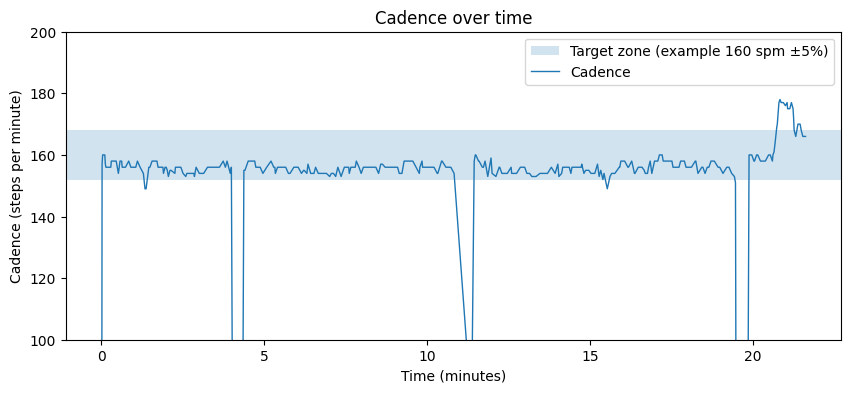

Time in target zone (while moving): 92 %


In [ ]:
# Read the first run
run_table = read_records(files[0])
start_time = run_table["timestamp"][0]

minutes = []
cadences = []

for index, row in run_table.iterrows():
    # Time since the start of the run, in minutes
    time_passed = row["timestamp"] - start_time
    minutes.append(time_passed.total_seconds() / 60)

    # Cadence in steps per minute
    fraction = row["fractional_cadence"]
    if pd.isna(fraction):
        fraction = 0
    cadences.append((row["cadence"] + fraction) * 2)

# Example target zone: 160 spm +/- 5%
target = 160
low = target * 0.95
high = target * 1.05

# Draw the chart
plt.figure(figsize=(10, 4))
plt.axhspan(low, high, alpha=0.2, label="Target zone (example 160 spm ±5%)")
plt.plot(minutes, cadences, linewidth=1, label="Cadence")
plt.xlabel("Time (minutes)")
plt.ylabel("Cadence (steps per minute)")
plt.title("Cadence over time")
plt.ylim(100, 200)
plt.legend()
plt.show()

# % of time in the target zone (only while moving)
moving_count = 0
in_zone_count = 0
for i in range(len(cadences)):
    if run_table["enhanced_speed"][i] <= 1.0:
        continue    # skip stops, where cadence drops to 0
    moving_count = moving_count + 1
    if low <= cadences[i] <= high:
        in_zone_count = in_zone_count + 1

percent_in_zone = in_zone_count / moving_count * 100
print("Time in target zone (while moving):", round(percent_in_zone), "%")

These fields could identify a runner and must **not** be stored.

In [ ]:
# Privacy check: does each file contain information that could identify a runner?
for file_path in files:
    run_table = read_records(file_path)

    # 1. Check for GPS location
    if "position_lat" in run_table.columns:
        has_gps = True
    else:
        has_gps = False

    # 2. Check for the watch serial number
    fit_file = fitparse.FitFile(file_path)
    has_serial_number = False
    for message in fit_file.get_messages("file_id"):
        for field in message:
            if field.name == "serial_number" and field.value is not None:
                has_serial_number = True

    print(file_path, "| GPS:", has_gps, "| serial number:", has_serial_number)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit | GPS: True | serial number: True
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit | GPS: True | serial number: True
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit | GPS: True | serial number: True


## Findings
1. Cadence is saved for one foot, so multiply by 2 for steps per minute.
2. Running dynamics (stride length, vertical oscillation, ground contact time) are not in the sample files. We need a new test file.
3. Data is saved every 3 to 7 seconds, not every second.
4. When the runner stops, cadence drops to 0. Ignore these points in averages and % in zone.
5. Height and weight are in the file, so they can go in the CSV export.
6. No runner name was found, but GPS and the watch serial number are there, so both must be removed.
7. Target cadence and feedback visible/hidden are not in the files yet. They will come from Nick's WCH-13.

# Part 2: WEB-15, prepare sample run data

Turns two runs (Forerunner 735XT, with running dynamics) into JSON files the web team can use to build pages before the upload works.
GPS, the watch serial number and the runner's name are not saved. Both runs use runner ID R001.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Unzip two files from your Drive folder into new_sample_runs
!unzip -o -q "/content/drive/MyDrive/capstone_project/"*1705616697*.zip -d /content/new_sample_runs
!unzip -o -q "/content/drive/MyDrive/capstone_project/"*1716914712*.zip -d /content/new_sample_runs

# Find the two FIT files
new_files = sorted(glob.glob("/content/new_sample_runs/*.fit"))
print(len(new_files), "files found")
new_files

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
2 files found


['/content/new_sample_runs/1705616697_ACTIVITY.fit',
 '/content/new_sample_runs/1716914712_ACTIVITY.fit']

In [ ]:
# Garmin saves the watch model as a number, so we turn it into a name
watch_names = {2158: "Forerunner 735XT"}


def read_summary(file_path, runner_id):
    # The three parts of the file we need
    session = get_first_message(file_path, "session")       # run summary
    profile = get_first_message(file_path, "user_profile")  # height and weight
    device = get_first_message(file_path, "file_id")        # watch model

    # Average cadence: whole number + fraction, then x2 for steps per minute
    fraction = session.get("avg_fractional_cadence")
    if fraction is None:
        fraction = 0
    average_cadence = (session["avg_running_cadence"] + fraction) * 2

    # Watch model name (or the number if we don't know the name)
    product = device.get("garmin_product")
    device_model = watch_names.get(product, str(product))

    # The run summary (no GPS, no serial number, no name)
    summary = {
        "runner_id": runner_id,
        "device_model": device_model,
        "start_time": str(session["start_time"]),
        "duration_s": round(session["total_timer_time"]),
        "distance_m": round(session["total_distance"]),
        "avg_cadence_spm": round(average_cadence),
        "avg_heart_rate": session.get("avg_heart_rate"),
        "height_m": profile.get("height"),
        "body_mass_kg": profile.get("weight"),
    }
    return summary


read_summary(new_files[0], "R001")

{'runner_id': 'R001',
 'device_model': 'Forerunner 735XT',
 'start_time': '2017-04-30 05:39:20',
 'duration_s': 1326,
 'distance_m': 5007,
 'avg_cadence_spm': 168,
 'avg_heart_rate': 176,
 'height_m': 1.75,
 'body_mass_kg': 76.0}

In [ ]:
def read_points(file_path):
    # Open the FIT file
    fit_file = fitparse.FitFile(file_path)

    # This list will hold one data point for each moment of the run
    points = []
    start_time = None

    # Go through every 'record' message (the moment-by-moment data)
    for record in fit_file.get_messages("record"):

        # Put all the fields of this moment into a simple dictionary
        values = {}
        for field in record:
            values[field.name] = field.value

        # Remember when the run started
        if start_time is None:
            start_time = values["timestamp"]

        # Seconds since the start of the run
        elapsed = values["timestamp"] - start_time

        # Cadence: whole number + fraction, then x2 for steps per minute
        cadence = values.get("cadence")
        fraction = values.get("fractional_cadence")
        if fraction is None:
            fraction = 0
        if cadence is not None:
            cadence = (cadence + fraction) * 2

        # Altitude: round to 1 decimal place
        altitude = values.get("enhanced_altitude")
        if altitude is not None:
            altitude = round(altitude, 1)

        # step_length is in mm, so divide by 1000 to get metres
        stride_length = values.get("step_length")
        if stride_length is not None:
            stride_length = stride_length / 1000

        # vertical_oscillation is in mm, so divide by 10 to get cm
        vertical_oscillation = values.get("vertical_oscillation")
        if vertical_oscillation is not None:
            vertical_oscillation = vertical_oscillation / 10

        # stance_time is already in milliseconds
        ground_contact = values.get("stance_time")

        # Save only what we're allowed to keep (no GPS)
        point = {
            "elapsed_s": round(elapsed.total_seconds()),
            "cadence_spm": cadence,
            "speed_mps": values.get("enhanced_speed"),
            "heart_rate": values.get("heart_rate"),
            "distance_m": values.get("distance"),
            "altitude_m": altitude,
            "stride_length_m": stride_length,
            "vertical_oscillation_cm": vertical_oscillation,
            "ground_contact_ms": ground_contact,
        }
        points.append(point)

    return points


points = read_points(new_files[0])
print(len(points), "data points")
points[:3]

294 data points


[{'elapsed_s': 0,
  'cadence_spm': 93.0,
  'speed_mps': 0.0,
  'heart_rate': 66,
  'distance_m': 0.4,
  'altitude_m': -7.8,
  'stride_length_m': 0.595,
  'vertical_oscillation_cm': 2.92,
  'ground_contact_ms': 614.0},
 {'elapsed_s': 1,
  'cadence_spm': 93.0,
  'speed_mps': 0.056,
  'heart_rate': 68,
  'distance_m': 1.32,
  'altitude_m': -7.6,
  'stride_length_m': 0.595,
  'vertical_oscillation_cm': 2.92,
  'ground_contact_ms': 614.0},
 {'elapsed_s': 2,
  'cadence_spm': 93.0,
  'speed_mps': 0.065,
  'heart_rate': 73,
  'distance_m': 3.43,
  'altitude_m': -7.6,
  'stride_length_m': 0.595,
  'vertical_oscillation_cm': 2.92,
  'ground_contact_ms': 614.0}]

In [ ]:
# Make a folder for the JSON files
os.makedirs("/content/sample-data", exist_ok=True)

run_number = 1

for file_path in new_files:

    # Get the summary and the data points
    run = read_summary(file_path, "R001")
    run["points"] = read_points(file_path)

    # Save it as a JSON file, for example R001_run1.json
    output_path = "/content/sample-data/R001_run" + str(run_number) + ".json"
    with open(output_path, "w") as output_file:
        json.dump(run, output_file, indent=2)

    print("Saved", output_path, "with", len(run["points"]), "points")
    run_number = run_number + 1

Saved /content/sample-data/R001_run1.json with 294 points
Saved /content/sample-data/R001_run2.json with 277 points


In [ ]:
# Check each JSON file: how many points, the average cadence, and no private data
for output_path in sorted(glob.glob("/content/sample-data/*.json")):

    # Read the file as text
    with open(output_path) as input_file:
        text = input_file.read()
    run = json.loads(text)

    # Make sure there's no GPS or serial number anywhere in the file
    has_gps = "position_lat" in text or "position_long" in text
    has_serial = "serial_number" in text

    print(output_path, "| points:", len(run["points"]), "| avg cadence:", run["avg_cadence_spm"], "| GPS:", has_gps, "| serial number:", has_serial)

/content/sample-data/R001_run1.json | points: 294 | avg cadence: 168 | GPS: False | serial number: False
/content/sample-data/R001_run2.json | points: 277 | avg cadence: 172 | GPS: False | serial number: False


In [ ]:
# Copy the JSON files to your Drive so they're not lost when Colab closes
!mkdir -p "/content/drive/MyDrive/capstone_project/sample-data"
!cp /content/sample-data/*.json "/content/drive/MyDrive/capstone_project/sample-data/"
!ls "/content/drive/MyDrive/capstone_project/sample-data"

R001_run1.json	R001_run2.json
